# HST Calibration Assignment  

In [126]:
import os
import numpy as np
from astropy.io import fits
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd

### Loading Files and Creating Dictionary

In [127]:
cal_folder= Path("hst-calibration")
proc_cal_folder = Path("hst-processed") / 'Calibrated Files'
science_folder = Path("hst-processed") / "Provided Science Ready Files"

cal_set = {
    "ubai2505m": os.path.join(cal_folder, "ubai2505m"),
    "ubai2507m": os.path.join(cal_folder, "ubai2507m"),
    "ubai2508m": os.path.join(cal_folder, "ubai2508m"),
}

science_ready_files = {
    Path(f).stem.split("_")[0]: science_folder/f
    for f in os.listdir(science_folder)
    if f.lower().endswith(".fits")
}

In [128]:
def load_calibration_files(cal_sets):
    result = {}

    for name, cal_path in cal_sets.items():
        folder = Path(cal_path)

        file_dict = {
            Path(f).stem.rsplit("_", 1)[-1].upper(): folder/f
            for f in os.listdir(folder)
        }

        result[name] = file_dict

    return result

cal_file_dict = load_calibration_files(cal_set)


In [129]:
cal_file_dict, science_ready_files 

({'ubai2505m': {'ATODFILE': WindowsPath('hst-calibration/ubai2505m/ubai2505m_atodfile.fits'),
   'BIASFILE': WindowsPath('hst-calibration/ubai2505m/ubai2505m_biasfile.fits'),
   'BLEVFILE': WindowsPath('hst-calibration/ubai2505m/ubai2505m_blevfile.fits'),
   'DARKFILE': WindowsPath('hst-calibration/ubai2505m/ubai2505m_darkfile.fits'),
   'FLATFILE': WindowsPath('hst-calibration/ubai2505m/ubai2505m_flatfile.fits'),
   'MASKFILE': WindowsPath('hst-calibration/ubai2505m/ubai2505m_maskfile.fits'),
   'RAW': WindowsPath('hst-calibration/ubai2505m/ubai2505m_raw.fits')},
  'ubai2507m': {'ATODFILE': WindowsPath('hst-calibration/ubai2507m/ubai2507m_atodfile.fits'),
   'BIASFILE': WindowsPath('hst-calibration/ubai2507m/ubai2507m_biasfile.fits'),
   'BLEVFILE': WindowsPath('hst-calibration/ubai2507m/ubai2507m_blevfile.fits'),
   'DARKFILE': WindowsPath('hst-calibration/ubai2507m/ubai2507m_darkfile.fits'),
   'FLATFILE': WindowsPath('hst-calibration/ubai2507m/ubai2507m_flatfile.fits'),
   'MASKFIL

In [130]:
def load_fits(path):
    with fits.open(path) as hdul:
        main_header = hdul[0].header

        # finds extension with data in it
        for hdu in hdul:
            if hdu.data is not None:
                return hdu.data.astype(float), main_header
            
paths = cal_file_dict['ubai2507m']
raw, raw_header = load_fits(paths['RAW'])
bias, bias_header = load_fits(paths['BIASFILE'])
mask, mask_header = load_fits(paths['MASKFILE'])
blev, blev_header = load_fits(paths['BLEVFILE'])
flat, flat_header = load_fits(paths['FLATFILE'])
dark, dark_header = load_fits(paths['DARKFILE'])

### For Visualisation...

In [131]:
def show_image(img, title, vmin=0, vmax=20):
    plt.figure(figsize=(6,6))
    plt.imshow(img, cmap="inferno", origin="lower", vmin=vmin, vmax=vmax)
    plt.title(title)
    plt.colorbar()
    plt.show()


# for viewing result
def per_norm(image, pmax=99, pmin=1):

    res = np.asarray(image, dtype=np.float64)
    vmin, vmax = np.percentile(image, (pmin, pmax))
    norm = (res - vmin) / (vmax - vmin)

    return np.clip(norm, 0, 1)

### 1. Mask invalid data with MASKFILE

In [132]:
def apply_mask(raw_chip, mask_chip):
    masked = raw_chip.copy()
    masked[mask_chip != 0] = np.nan
    return masked

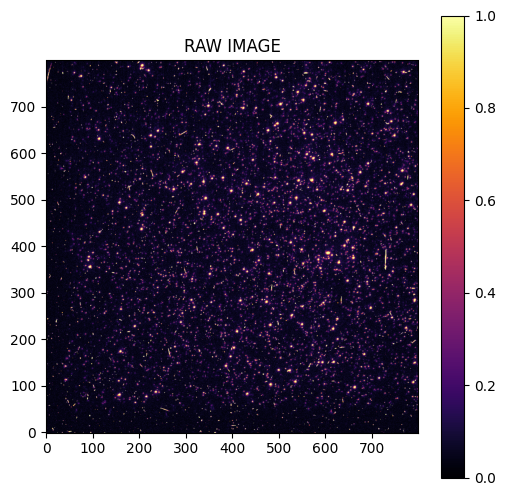

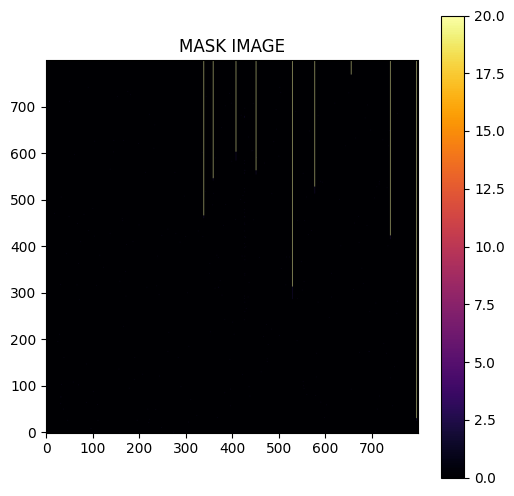

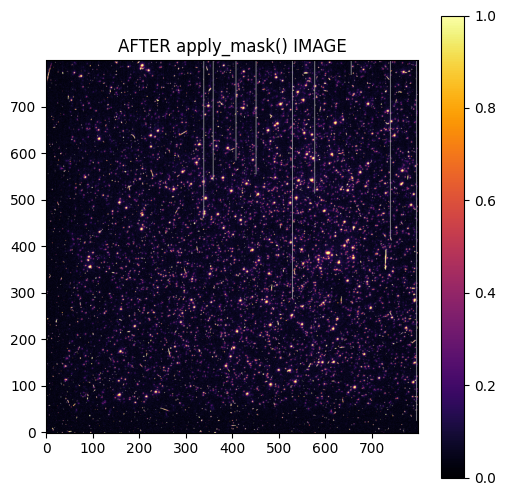

In [133]:
raw1 = per_norm(raw[0])
masked1 = apply_mask(raw1, mask[0])
masked = apply_mask(raw[0], mask[0]) # actually used for further calibration

#adding normalisation to see result better
show_image(raw1, 'RAW IMAGE', None, None)
show_image(mask[0], 'MASK IMAGE')
show_image(masked1, 'AFTER apply_mask() IMAGE', None, None)

### 3. Bias level with BLEVFILE

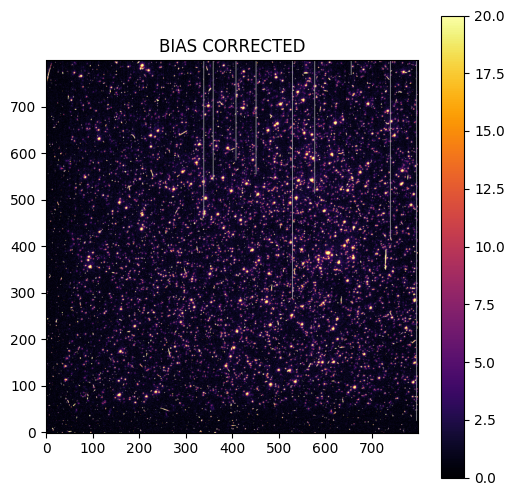

In [134]:
def parse_blev_file(blev, chip=0):

    # handles both (4, 800, 14) and (800, 14) shaped files
    if blev.ndim == 3:
        overscan = blev[chip][9:790, 8:14]
    else:
        overscan = blev[9:790, 8:14]

    overscan[overscan == 0] = np.nan
    odd_vals = overscan[:, 1::2]
    even_vals = overscan[:, ::2]

    return np.mean(odd_vals), np.mean(even_vals)


  #---------------------------------------------------------------------

def apply_bias_corr(image, odd_mean, even_mean):

  corrected = image.copy()
  ny, nx = corrected.shape
    
  for x in range(nx):
    if x % 2 == 0:
      corrected[:, x] -= odd_mean
    else:      
      corrected[:, x] -= even_mean

  return corrected

odd_mean, even_mean = parse_blev_file(blev, chip=0)
bias_corrected = apply_bias_corr(masked, odd_mean, even_mean)
show_image(bias_corrected, "BIAS CORRECTED")

<!-- ### 4. Remove bias image with BIASFILE -->

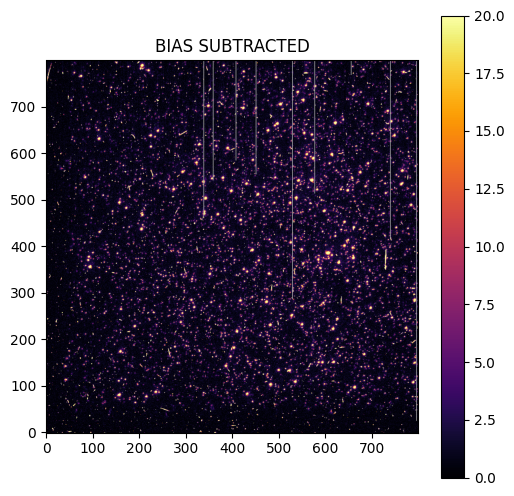

In [135]:
def subtract_bias(image, bias):
    return image - bias

bias_subtracted = subtract_bias(bias_corrected, bias[0])
show_image(bias_subtracted, 'BIAS SUBTRACTED')

### 5. Subtract dark with DARKFILE 

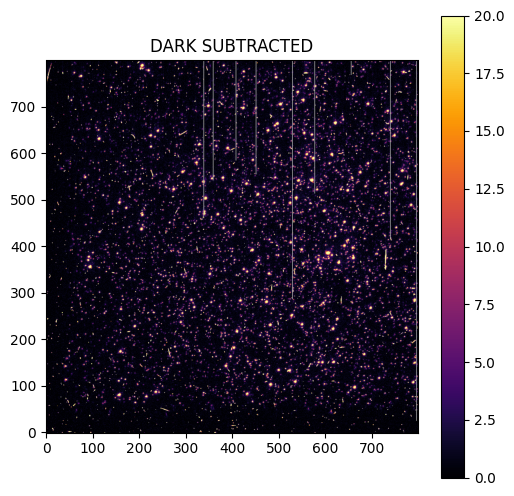

In [136]:
def subtract_dark(image, dark, exptime):
    return image - dark*exptime

exptime = raw_header["EXPTIME"]
dark_corrected = subtract_dark(bias_subtracted, dark[0], exptime)
show_image(dark_corrected, 'DARK SUBTRACTED')

### 6. Flatfield correction with FLATFILE

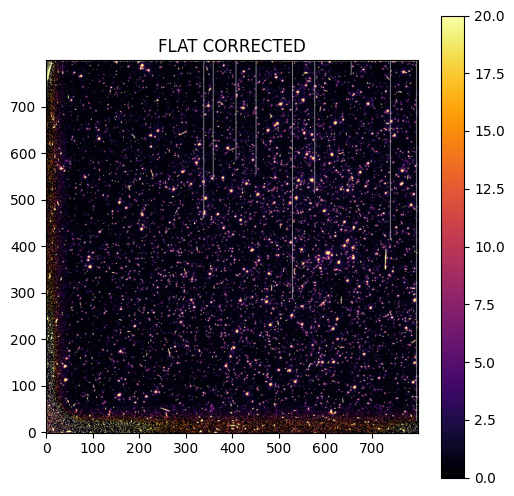

In [137]:
def apply_flat(image, flat):
    return image*flat

flat_corrected = apply_flat(dark_corrected, flat[0])
show_image(flat_corrected, 'FLAT CORRECTED')

### Photometry calibration with PHOTTAB

In [138]:
phottab_data = {
    "Filter": ["F336W", "F555W"],
    "PHOTFLAM": [1.115396e-16, 6.920538e-18],
    "PHOTZPT": [-21.1, -21.1], 
    "PHOTPLAM": [3359.474, 5442.934],
    "PHOTBW": [204.4908, 522.2513],
    "ZP_CORR": [-0.03288031, 0.02655506]
}

phottab = pd.DataFrame(phottab_data)

filter = raw_header['FILTNAM1']
file_phot = phottab.loc[phottab["Filter"] == filter].iloc[0]
PHOTFLAM = float(file_phot["PHOTFLAM"])
PHOTZPT  = float(file_phot["PHOTZPT"])
ZP_CORR  = float(file_phot["ZP_CORR"])

C:\Users\odunu\AppData\Local\Temp\ipykernel_12216\2151463750.py:3: RuntimeWarning: invalid value encountered in log10
  mag = -2.5 * np.log10(flux) + photzpt + zp_corr


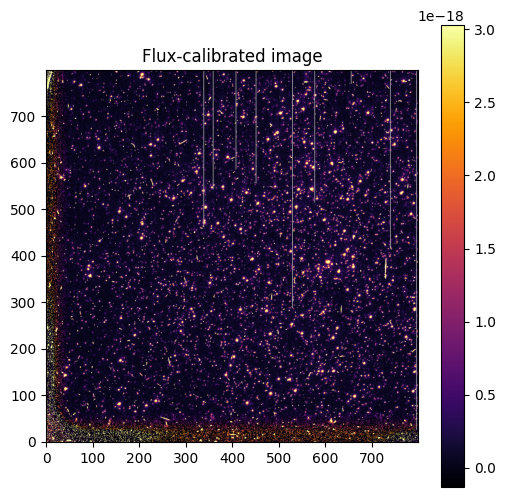

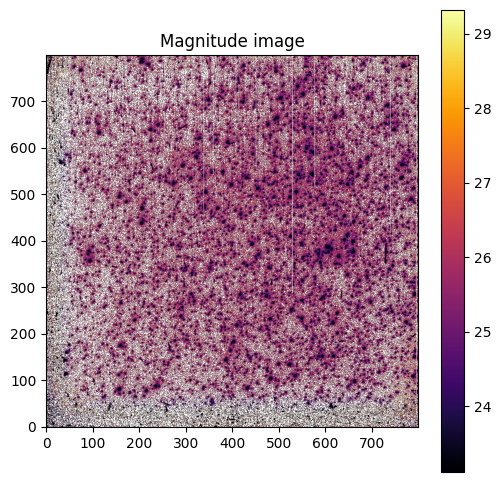

In [139]:
def apply_photometry(image, exptime, photflam, photzpt, zp_corr):
    flux = (image / exptime)*photflam
    mag = -2.5 * np.log10(flux) + photzpt + zp_corr
    return flux, mag

flux, mag = apply_photometry(flat_corrected, exptime, PHOTFLAM, PHOTZPT, ZP_CORR)
lo, hi = np.nanpercentile(flux, [5, 98])
show_image(flux, "Flux-calibrated image", lo, hi)
lo, hi = np.nanpercentile(mag, [5, 98])
show_image(mag, "Magnitude image", lo, hi)

In [140]:
def run_calibration(calib, folder_name, dir=None):
 
    raw, raw_header  = load_fits(calib["RAW"])
    mask, _ = load_fits(calib["MASKFILE"])
    bias, _ = load_fits(calib["BIASFILE"])
    dark, _ = load_fits(calib["DARKFILE"])
    flat, _ = load_fits(calib["FLATFILE"])
    blev, _ = load_fits(calib["BLEVFILE"])

    exptime = raw_header["EXPTIME"]
    final = []

    for chip in range(4):
        img = raw[chip]
        img = apply_mask(img, mask[chip])
        odd, even = parse_blev_file(blev, chip)
        img = apply_bias_corr(img, odd, even)
        img = subtract_bias(img, bias[chip])
        img = subtract_dark(img, dark[chip], exptime)
        img = apply_flat(img, flat[chip])

        final.append(img)
    
    final = np.array(final)

    if dir is not None:
        final_path = dir / f"calibrated_{folder_name}.fits"
        fits.writeto(final_path, final, raw_header, overwrite=True)
    
    return final

### Running Full Calibration and Comparison (Reference vs Calibration)

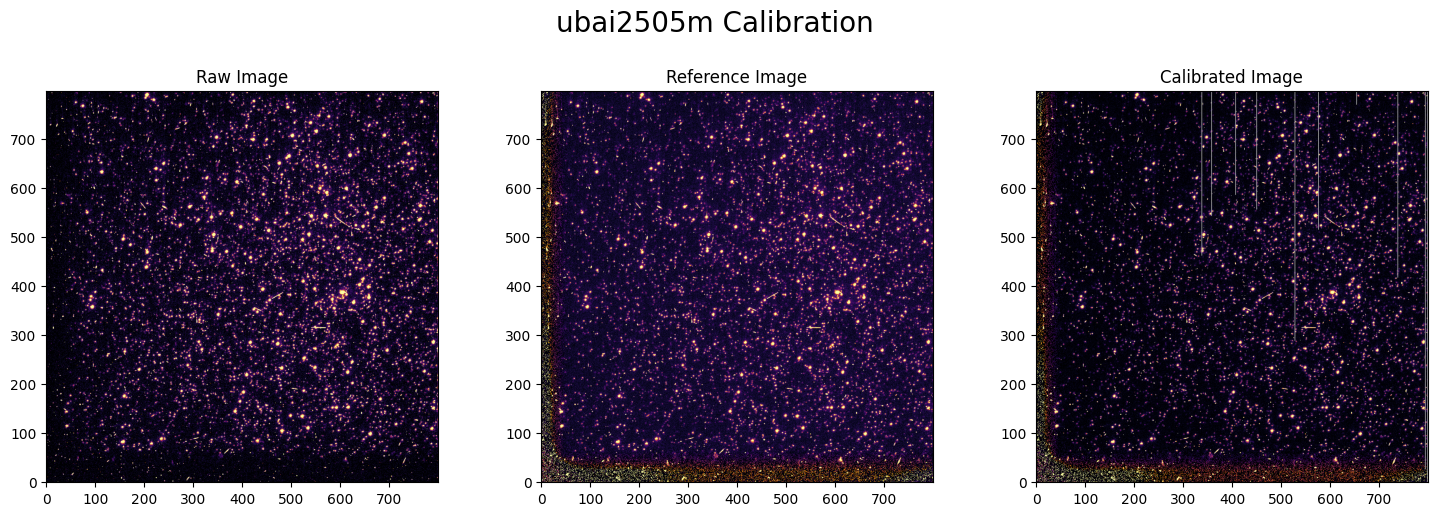

Calibrated mean/std: 2.3387630098068537 41.075606597248544
Reference mean/std: 2.30949380071835 41.006299318277314
Difference mean/std: 0.027060195005525686 0.21067007919104144


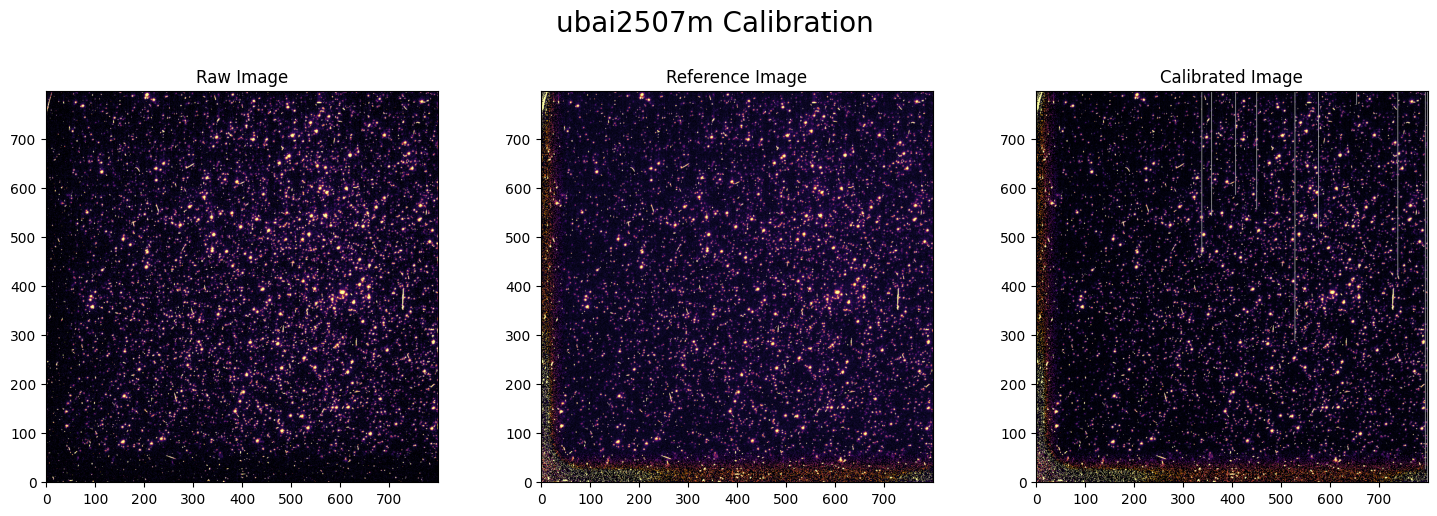

Calibrated mean/std: 3.315333299899916 83.09874508069733
Reference mean/std: 3.2762996988777173 82.90295569465674
Difference mean/std: 0.029162173856591166 0.2490136660221064


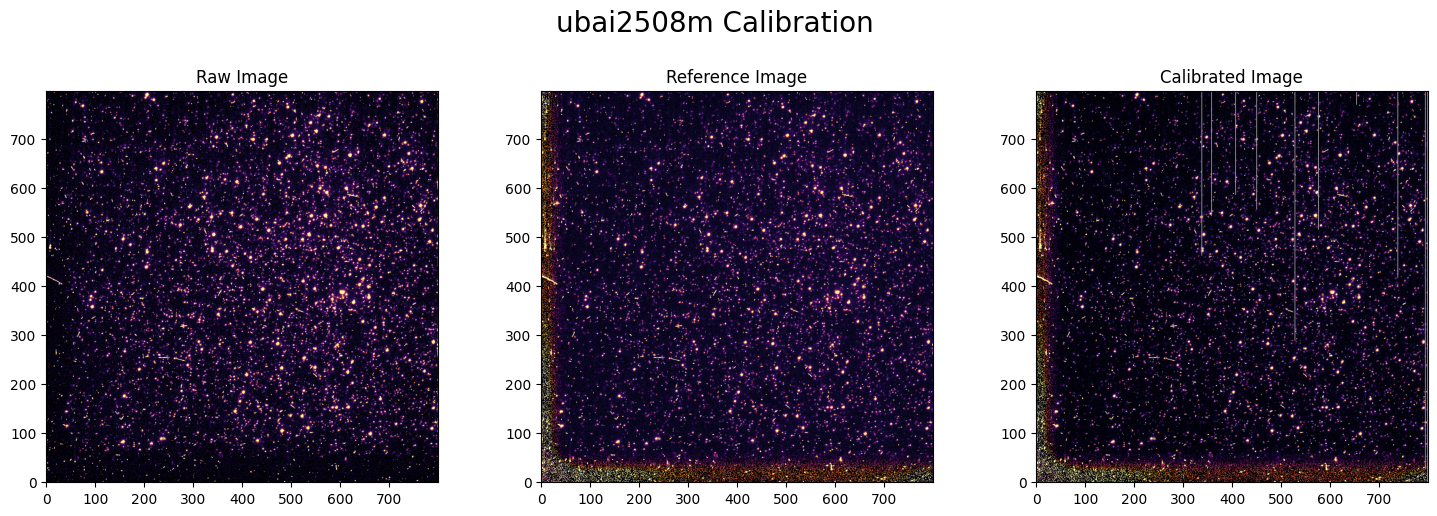

Calibrated mean/std: 4.45980842996478 262.62476128066294
Reference mean/std: 4.413787572344356 261.84289017913113
Difference mean/std: 0.030943192154201545 0.27982623096817355


In [141]:
for i in cal_file_dict.keys():
    final_img_cal = run_calibration(cal_file_dict[i], i, proc_cal_folder)
    raw_img, _ = load_fits(cal_file_dict[i]['RAW'])
    ref_img, _ = load_fits(science_ready_files[i])

    images  = {
        'Raw Image': raw_img[0],
        'Reference Image': ref_img,
        'Calibrated Image': final_img_cal[0]
    }

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for ax, (name, data) in zip(axes.flat, images.items()):
        if name == 'Calibrated Image':
            ax.imshow(data, origin="lower", cmap="inferno", vmin=0, vmax=20)
        else:
            lo, hi = np.percentile(data, [5,98])
            ax.imshow(data, origin="lower", cmap="inferno", vmin=lo, vmax=hi)
        ax.set_title(name)

    fig.suptitle(f'{i} Calibration \n', fontsize = 20)
    plt.tight_layout()
    plt.show()

    diff = final_img_cal[0] - ref_img
    print("Calibrated mean/std:", np.nanmean(final_img_cal[0]), np.nanstd(final_img_cal[0]))
    print("Reference mean/std:", np.nanmean(ref_img), np.nanstd(ref_img))
    print("Difference mean/std:", np.nanmean(diff), np.nanstd(diff))


Across the three datasets (ubai2505m, ubai2507m, and ubai2508m), the calibrated images match their science‑ready reference frames well. The mean and standard deviation differ by less than 1%, showing that the calibration pipeline reproduces the main characteristics of the reference data. The results shown here do not include the final photometric calibration, since that step puts the data on a different flux scale and would not be suitable for direct comparison.

The calibrated images have slightly higher mean values, which is expected after bias‑level removal and flat‑field correction. The faint vertical streaks visible in all three calibrated frames highlight areas where measurements are less reliable, but they do not significantly affect the overall accuracy. These streaks can be removed for cleaner visual presentation if needed. The difference metrics (mean ≈ 0.03, std ≈ 0.25) show that the calibrated and reference images agree extremely well. This confirms that the bias, dark, and flat corrections are working well.